# D-2: Did the Pilates campaign bring engaged, long-term customers? (Q7)
**Cohort:** everyone whose `signup_date` falls in the campaign window (Jan 6 – Mar 31, 2025).
**Compare:** `acquisition_channel == "Pilates Campaign"` (360) vs customers from other channels who signed up
in the **same weeks** (417), so season and store conditions are the same for both groups. Slide 9.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

from src import config as C
from src.metrics import load

OUT = ROOT / "results" / "d_customers_arr"
OUT.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, GRID = "#0b0b0b", "#5f5e5a", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "font.size": 11,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "lines.linewidth": 2,
})

In [2]:
customers = load("customers")
visits = load("visits")

cohort = customers[customers["signup_date"].between(C.PILATES_START, C.PILATES_END)].copy()
cohort["group"] = cohort["acquisition_channel"].eq("Pilates Campaign").map(
    {True: "Pilates Campaign", False: "Other channels, same weeks"})
cohort.groupby("group").size()

group
Other channels, same weeks    417
Pilates Campaign              360
dtype: int64

## 1. Who they are
Pilates-campaign customers are similar in age to the comparison group. All list Pilates as an interest, and
fewer joined loyalty.

In [3]:
profile = cohort.groupby("group").agg(
    customers=("customer_id", "size"),
    pilates_interest=("interest_pilates", "mean"),
    loyalty_member=("is_member", "mean"),
    age_18_34=("age_band", lambda s: s.isin(["18-24", "25-34"]).mean()),
).round(2)
profile

,customers,pilates_interest,loyalty_member,age_18_34
group,,,,
"Other channels, same weeks",417,0.08,0.72,0.53
Pilates Campaign,360,1.00,0.56,0.57


## 2. Do they come back?
Visits are matched to each customer's own signup date. "Came back within N days" = any visit 1 to N days after signup.

In [4]:
v = visits.merge(cohort[["customer_id", "group"]], on="customer_id")
v["days"] = (v["date"] - v["signup_date"]).dt.days

for d in [90, 180, 365]:
    returned = v.loc[v["days"].between(1, d), "customer_id"].unique()
    cohort[f"came_back_{d}d"] = cohort["customer_id"].isin(returned)
cohort["one_visit_only"] = cohort["n_visits"] == 1
cohort["last_visit_in_campaign"] = cohort["last_visit"] <= C.PILATES_END

first_year = (v[v["days"] <= 365].groupby(["customer_id", "group"])
              .agg(revenue=("revenue", "sum"), profit=("profit", "sum"), visits=("transaction_id", "size"))
              .reset_index())

retention = pd.concat([
    cohort.groupby("group")[["came_back_90d", "came_back_180d", "came_back_365d", "one_visit_only",
                             "last_visit_in_campaign", "churned"]].mean().mul(100).round(1),
    first_year.groupby("group")[["visits", "revenue", "profit"]].mean().round(1)
        .rename(columns=lambda c: f"first_year_{c}_per_customer"),
], axis=1)
retention.T

group,"Other channels, same weeks",Pilates Campaign
came_back_90d,53.7,43.3
came_back_180d,69.8,50.0
came_back_365d,80.6,52.2
one_visit_only,16.8,46.9
last_visit_in_campaign,23.0,63.9
churned,59.5,90.3
first_year_visits_per_customer,6.3,3.1
first_year_revenue_per_customer,841.6,368.0
first_year_profit_per_customer,496.2,225.8


## 3. Retention curve: share of customers who visit in each month after signup

In [5]:
v["month_after"] = v["days"] // 30
curve = (v[v["month_after"].between(1, 18)].groupby(["group", "month_after"])["customer_id"].nunique()
         .unstack(0).div(cohort.groupby("group").size()) * 100)
curve.round(1).iloc[[0, 2, 5, 11, 17]]

group,"Other channels, same weeks",Pilates Campaign
month_after,,
1,25.4,17.5
3,27.3,12.5
6,27.8,7.2
12,21.6,5.0
18,17.7,5.0


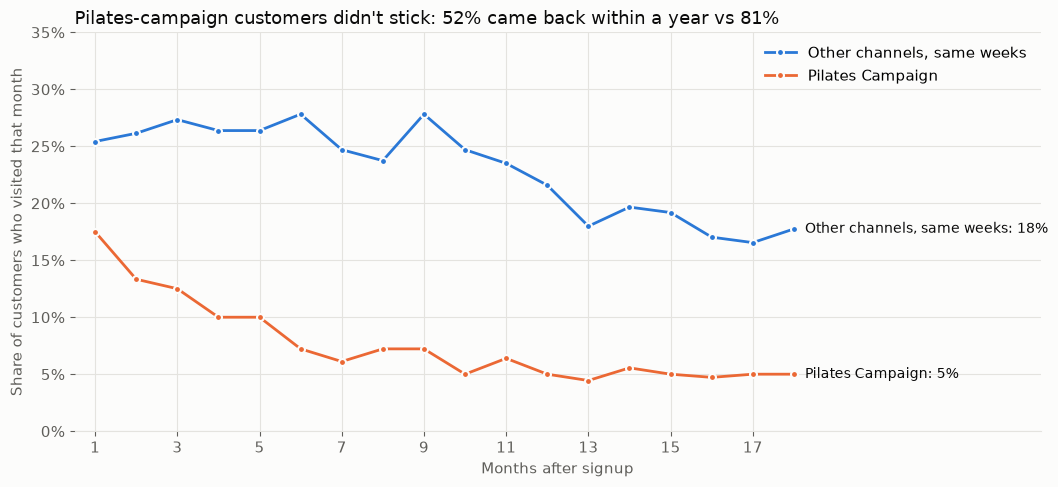

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))
series = [("Other channels, same weeks", BLUE), ("Pilates Campaign", ORANGE)]
for name, colr in series:
    ax.plot(curve.index, curve[name], color=colr, label=name, marker="o", ms=5, mec="#fcfcfb", mew=1.5)
    y = curve[name].iloc[-1]
    ax.annotate(f"{name}: {y:.0f}%", (curve.index[-1], y), xytext=(8, 0), textcoords="offset points",
                va="center", color=INK, fontsize=10)
ax.set_xlim(0.5, 24)
ax.set_xticks(range(1, 19, 2))
ax.set_ylim(0, 35)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Months after signup")
ax.set_ylabel("Share of customers who visited that month")
ax.legend(loc="upper right", frameon=False)
p, o = retention.loc["Pilates Campaign"], retention.loc["Other channels, same weeks"]
ax.set_title(f"Pilates-campaign customers didn't stick: {p['came_back_365d']:.0f}% came back "
             f"within a year vs {o['came_back_365d']:.0f}%", loc="left", color=INK, fontsize=13)
fig.tight_layout()
fig.savefig(OUT / "d2_pilates_retention.png", dpi=200)
plt.show()

## 4. What the campaign is worth today
ARR contribution as of Oct 2026, and total first-year profit of each cohort.
(The data has no campaign cost, so this is value delivered, not ROI.)

In [7]:
value = cohort.groupby("group").agg(
    customers=("customer_id", "size"),
    arr_now_total=("arr_12m", "sum"),
    arr_now_per_customer=("arr_12m", "mean"),
)
value["first_year_profit_total"] = first_year.groupby("group")["profit"].sum()
value.round(0)

,customers,arr_now_total,arr_now_per_customer,first_year_profit_total
group,,,,
"Other channels, same weeks",417,246241.0,591.0,206927.0
Pilates Campaign,360,53403.0,148.0,81294.0


## 5. What they bought
Share of each group's purchase revenue by product activity.

In [8]:
lines = load()
buys = lines[(lines["row_type"] == C.PURCHASE) & lines["customer_id"].isin(cohort["customer_id"])]
buys = buys.merge(cohort[["customer_id", "group"]], on="customer_id")
mix = buys.groupby(["activity", "group"])["revenue"].sum().unstack()
(mix / mix.sum() * 100).round(0)

group,"Other channels, same weeks",Pilates Campaign
activity,,
Lifestyle,28.0,18.0
Outdoor,20.0,13.0
Pilates,11.0,40.0
Run,24.0,18.0
Yoga,17.0,11.0
